# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
print("--- Primeras filas de 'plans' ---")
print(plans.head())

--- Primeras filas de 'plans' ---
  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [4]:
# mostrar las primeras 5 filas de users
print("\n--- Primeras filas de 'users' ---")
print(users.head())


--- Primeras filas de 'users' ---
   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [5]:
# mostrar las primeras 5 filas de usage
print("\n--- Primeras filas de 'usage' ---")
print(usage.head())


--- Primeras filas de 'usage' ---
   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
print("\n--- Información de plans ---")
plans.info()


--- Información de plans ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
print("\n--- Información de users ---")
users.info()


--- Información de users ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
print("\n--- Información de usage ---")
usage.info()


--- Información de usage ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("Valores nulos en users:\n", users.isna().sum())
print("Proporción de nulos en users:\n", users.isna().mean())

Valores nulos en users:
 user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de nulos en users:
 user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("\nValores nulos en usage:\n", usage.isna().sum())
print("Proporción de nulos en usage:\n", usage.isna().mean())


Valores nulos en usage:
 id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de nulos en usage:
 id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

--- DIAGNÓSTICO VALORES NULOS ---
users.churn_date (88% nulos): Ignorar, ya que los valores nulos son válidos y representan a los clientes que siguen activos en el servicio. Implementar estrategias para retener ese 12% de usuarios que abandonaron el servicio

usage.date (0.12% nulos): Eliminar los datos nulos, debido a que la proporción es insignificante (menor al 5%) y no afectará en absoluto las métricas globales.

usage.duration (55% nulos) y usage.length (44% nulos): Imputar, puesto que los vacíos ocurren de forma normal cuando el tipo de consumo es un mensaje (0 minutos) o una llamada (0 caracteres).

users.city (11.72% nulos): Investigar para imputar como 'Desconocido', ya que al ser menor al 30% es mejor etiquetarlos que borrar a esos usuarios y perder sus datos de consumo.



### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print("--- Resumen numérico: users ---")
print(users[['age']].describe())

--- Resumen numérico: users ---
               age
count  4000.000000
mean     33.739750
std     123.232257
min    -999.000000
25%      32.000000
50%      47.000000
75%      63.000000
max      79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
  Es una columna de identificación única para cada usuario. Al ser una clave o ID, sus métricas estadísticas no tienen un significado real de negocio.
- La columna `age` ...
Detectamos la presencia de un valor centinela evidente, ya que el valor mínimo registrado es -999. Esto distorsiona la media y la desviación estándar de la columna, por lo que este valor requerirá ser reemplazado por NaN en la etapa de limpieza.

In [13]:
import pandas as pd
df_usage = pd.read_csv("/datasets/usage.csv") 
# explorar columnas numéricas de usage
print(df_usage[['duration', 'length']].describe())

           duration        length
count  17924.000000  22104.000000
mean       5.202237     52.127398
std        6.842701     56.611183
min        0.000000      0.000000
25%        1.437500     37.000000
50%        3.500000     50.000000
75%        6.990000     64.000000
max      120.000000   1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
  Son variables de identificación únicas
- Las columnas ...
  No presentan valores sentinels negativos. El valor mínimo de 0 es completamente válido para llamadas perdidas o consumos mínimos. Sin embargo, la columna length muestra una desviación estándar alta y un máximo de 1490 que evidencia la presencia de outliers o consumos atípicos muy elevados respecto al comportamiento del 75% de los usuarios.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(col)
    print(users[col].unique())
    print()


city
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

plan
['Basico' 'Premium']



- La columna `city` ...
  Detectamos el valor sentinel '?' y valores nulos (nan) que enmascaran datos faltantes.
  Las etiquetas válidas corresponden a ciudades reales como Medellín, CDMX, Bogotá, GDL, MTY y Cali.
  Se recomienda reemplazar el carácter '?' por NaN o agrupar ambos bajo la etiqueta 'Desconocido'
- La columna `plan` ...
  No presenta inconsistencias ni valores nulos, mostrando una calidad de datos limpia.
  Contiene exactamente los dos planes comerciales de la empresa: 'Basico' y 'Premium'.


In [15]:
# explorar columna categórica de usage
print(usage['type'].unique())

['call' 'text']


- La columna `type` ...
  No presenta valores nulos ni caracteres sentinels, mostrando datos limpios.
  Contiene exactamente dos tipos de consumo de red válidos: 'call' y 'text'.
  Permite segmentar el uso de los clientes de forma directa y sin necesidad de correcciones adicionales.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

 
--- Diagnóstico de Valores Inválidos y Sentinels ---

- users.age: Se detectó el valor sentinel -999 en el valor mínimo de la columna. Se recomienda reemplazar estos valores por NaN y posteriormente imputarlos utilizando la mediana de la edad para no sesgar las estadísticas.
- users.city: Se detectó el valor sentinel '?' dentro de las categorías únicas de ciudades. Se recomienda homologar este carácter junto con los valores nan bajo una etiqueta uniforme como 'Desconocido' para limpiar los análisis geográficos.
- usage.duration y usage.length: No presentan valores sentinels, pero muestran ceros (0) válidos por llamadas perdidas y picos de consumo muy altos (outliers). Se recomienda mantenerlos ya que representan comportamiento real de usuarios.
- usage.type: No presenta ninguna inconsistencia, mostrando únicamente las categorías limpias y válidas de 'call' y 'text'.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')  # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce') # completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts())

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.
- Presencia de datos imposibles o anómalos: El año 2026 aparece 40 veces. Según las instrucciones, el dataset solo tiene registros válidos hasta el año 2024.
- Error de captura o inconsistencia temporal: Al tratarse de registros con fechas futuras que superan el límite establecido, estas 40 filas representan un claro error de captura o inconsistencia en el sistema de registro de usuarios.
- Distribución normal de los datos históricos: Los años 2022, 2023 y 2024 muestran una distribución muy uniforme y lógica, con alrededor de 1,314 a 1,330 registros por año, lo que valida que el grueso del dataset es consistente.


In [19]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts())

2024.0    39950
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

- Todos los registros pertenecen exclusivamente al año 2024 con un total de 39,950 filas.
- No presenta años futuros, negativos ni inconsistencias cronológicas, cumpliendo perfectamente con el límite establecido por el negocio.
- Indica que este dataset está limpio en su dimensión temporal y listo para ser cruzado con la información de los usuarios.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
  Sí, en el dataset users (columna reg_date) se detectó el año 2026 repetido 40 veces, lo cual es un año imposible considerando que el límite real de los datos guardados es hasta 2024. El dataset usage se encuentra limpio y concentrado correctamente en el año 2024.
- ¿Qué harías con ellas?
  Reemplazar el año 2026 por valores nulos (NaT / NaN) o eliminar esas 40 filas del análisis cronológico, ya que representan un claro error de captura en el sistema que alteraría cualquier métrica de crecimiento temporal.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)
# Verificar cambios
print(users['age'].describe())

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].unique())

['Medellín' <NA> 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']


In [23]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False))


2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
print("Nulos en 'duration' según el tipo de consumo:")
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().sum()))

print()

Nulos en 'duration' según el tipo de consumo:
type
call        0
text    22076
Name: duration, dtype: int64



In [25]:
# Verificación MAR en usage (Missing At Random) para length
print("Nulos en 'length' según el tipo de consumo:")
print(usage.groupby('type')['length'].apply(lambda x: x.isna().sum()))

Nulos en 'length' según el tipo de consumo:
type
call    17896
text        0
Name: length, dtype: int64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Las llamadas (call) tienen exactamente 0 nulos en duration, pero presentan 17,896 nulos en length. Por el contrario, los mensajes (text) tienen 0 nulos en length, pero acumulan 22,076 nulos en duration.

Se deben dejar como nulos y no se deben eliminar ni imputar con promedios. Los vacíos son lógicos y correctos para el negocio: un mensaje de texto no genera minutos de duración (duration = NaN) y una llamada telefónica no genera caracteres ni volumen de datos (length = NaN). Eliminar estas filas destruiría la mitad de la base de datos de forma incorrecta.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
print(usage_agg.head(3))

   user_id  is_text  is_call  duration
0    10000        7        3     23.70
1    10001        5       10     33.18
2    10002        5        2     10.74


In [27]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
print(usage_agg.head(3))

   user_id  cant_mensajes  cant_llamadas  cant_minutos_llamada
0    10000              7              3                 23.70
1    10001              5             10                 33.18
2    10002              5              2                 10.74


In [28]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
print(user_profile.head(5))

   user_id first_name last_name   age      city                      reg_date  \
0    10000     Carlos    Garcia  38.0  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres  53.0      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez  57.0      CDMX 2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez  69.0    Bogotá 2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres  63.0       GDL 2022-01-02 02:17:11.657914478   

      plan churn_date  cant_mensajes  cant_llamadas  cant_minutos_llamada  
0   Basico        NaN            7.0            3.0                 23.70  
1   Basico        NaN            5.0           10.0                 33.18  
2   Basico        NaN            5.0            2.0                 10.74  
3  Premium        NaN           11.0            3.0                  8.99  
4   Basico        NaN            4.0            3.0                  8.01  


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:
# Resumen estadístico de las columnas numéricas
columnas_interes = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada", "age"]
print("--- Resumen Estadístico de Uso Histórico ---")
print(user_profile[columnas_interes].describe())

print()

--- Resumen Estadístico de Uso Histórico ---
       cant_mensajes  cant_llamadas  cant_minutos_llamada          age
count    3999.000000    3999.000000           3999.000000  4000.000000
mean        5.524381       4.478120             23.317054    48.136000
std         2.358416       2.144238             18.168095    17.689919
min         0.000000       0.000000              0.000000    18.000000
25%         4.000000       3.000000             11.120000    33.000000
50%         5.000000       4.000000             19.780000    48.000000
75%         7.000000       6.000000             31.415000    63.000000
max        17.000000      15.000000            155.690000    79.000000



In [30]:
# Distribución porcentual del tipo de plan
print("--- Distribución Porcentual de Planes ---")
print(user_profile["plan"].value_counts(normalize=True))

--- Distribución Porcentual de Planes ---
Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

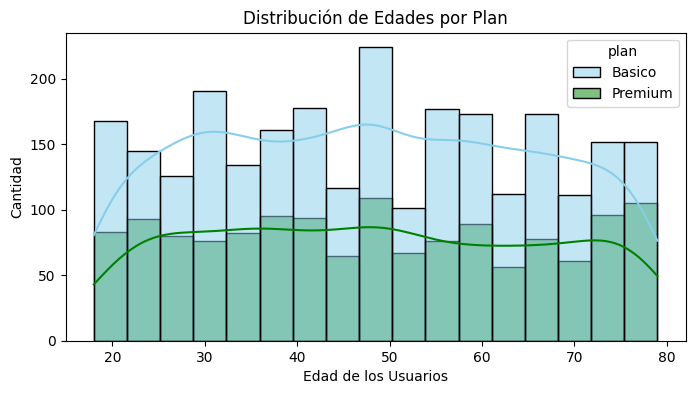

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="age", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de Edades por Plan")
plt.xlabel("Edad de los Usuarios")
plt.ylabel("Cantidad")
plt.show()

💡Insights: 
- Distribución: Simétrica. Aproximadamente uniforme en los rangos de edad activa
- No existe algún patrón o diferencia drástica en la edad de los usuarios según el plan. Tanto el plan Básico como el Premium muestran una distribución uniforme de clientes jóvenes, adultos y adultos mayores.


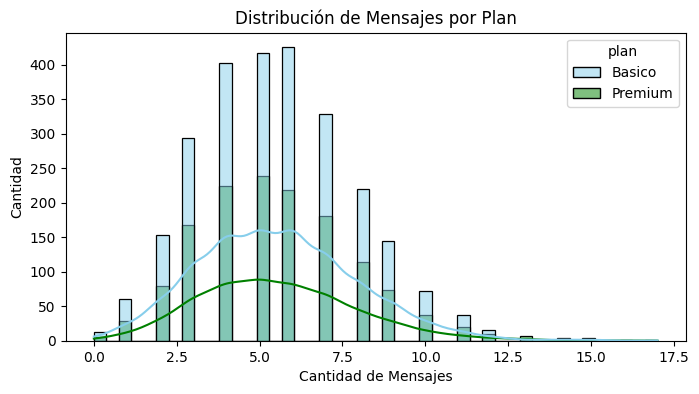

In [32]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de Mensajes por Plan")
plt.xlabel("Cantidad de Mensajes")
plt.ylabel("Cantidad")
plt.show()

💡Insights: 
- Distribución: Sesgada a la derecha. La mayoría de los usuarios envía pocos mensajes, y unos cuantos envían volúmenes muy altos.
- Los usuarios de plan Básico tienden a enviar menos mensajes y se concentran en las barras iniciales, mientras que en el plan Premium hay mayor proporción de usuarios distribuidos hacia consumos más altos.

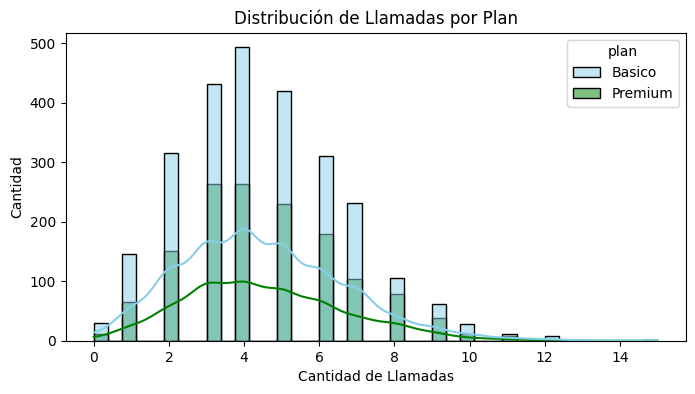

In [33]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de Llamadas por Plan")
plt.xlabel("Cantidad de Llamadas")
plt.ylabel("Cantidad")
plt.show()

💡Insights: 
- Distribución: Sesgada a la derecha. Forma de campana inclinada hacia los valores bajos de llamadas.
- Dentro del plan Premium, hay mayor proporción de usuarios que realizan un número elevado de llamadas. Los usuarios del plan Básico se concentran predominantemente en volúmenes de llamadas bajos a moderados.

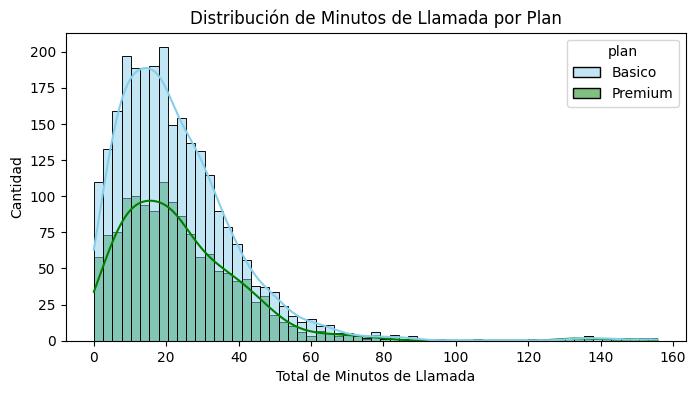

In [34]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de Minutos de Llamada por Plan")
plt.xlabel("Total de Minutos de Llamada")
plt.ylabel("Cantidad")
plt.show()

💡Insights: 
- Distribución: Sesgada a la derecha
- Los usuarios con plan Básico acumulan menor cantidad de minutos totales de conversación. Los clientes Premium reflejan colas más largas hacia la derecha, indicando llamadas más duraderas o frecuentes.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

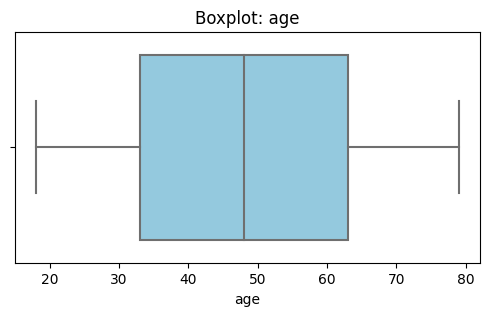

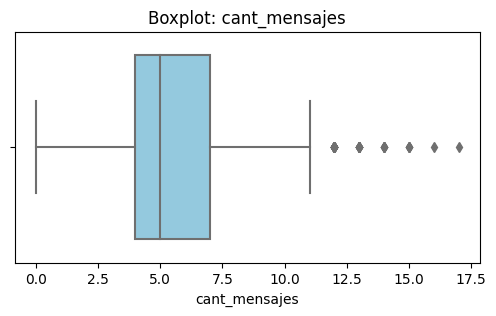

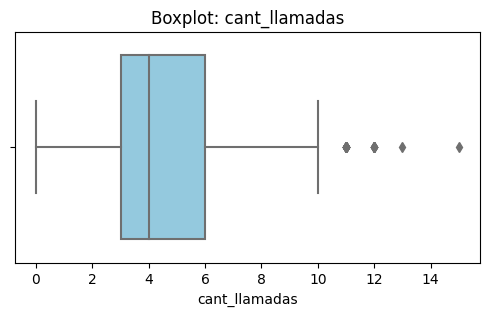

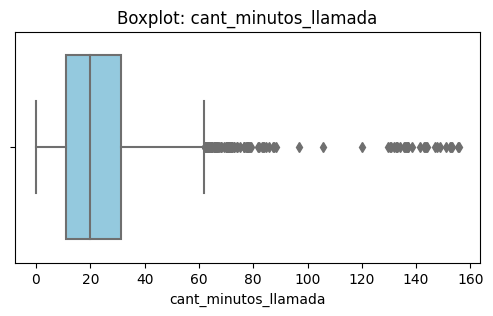

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
Age: No presenta outliers (todos los datos se encuentran dentro de los bigotes normales, ya que limpiamos el valor centinela -999).
cant_mensajes: Presenta outliers en el extremo derecho (valores atípicos altos).
cant_llamadas: Presenta outliers en el extremo derecho (valores atípicos altos).
cant_minutos_llamada: Presenta outliers en el extremo derecho (valores atípicos altos).


In [40]:
# Calcular límites con el método IQR
columnas_con_outliers = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

print("--- Límites Superiores (Método IQR) ---")
for col in columnas_con_outliers:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1


--- Límites Superiores (Método IQR) ---


In [41]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no

columnas_con_outliers = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

print("--- Límites Superiores (Método IQR) ---")
for col in columnas_con_outliers:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f"Límite superior para {col}: {limite_superior}")

--- Límites Superiores (Método IQR) ---
Límite superior para cant_mensajes: 11.5
Límite superior para cant_llamadas: 10.5
Límite superior para cant_minutos_llamada: 61.8575


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener los outliers porque un límite superior de 11.5 mensajes es un umbral muy bajo para el comportamiento real de un usuario móvil. Valores por encima de esta cifra representan consumos legítimos y esperados (especialmente en planes Premium), por lo que eliminarlos o truncarlos eliminaría información real sobre el comportamiento de uso de los clientes.
- cant_llamadas: mantener o no outliers, porqué? Mantener los outliers porque el límite de 10.5 llamadas es bajo. Realizar más de 10 llamadas en el periodo evaluado es un comportamiento común y orgánico de los usuarios. Estos datos atípicos reflejan la variabilidad natural del consumo de telefonía y no errores de captura del sistema.
- cant_minutos_llamada: mantener o no outliers, porqué? Mantener los outliers porque acumular más de 61.8 minutos de conversación en total es perfectamente factible para un cliente. Estos extremos representan a los usuarios de alto valor de la compañía, los cuales son esenciales para analizar la demanda de red y estructurar las tarifas de los planes.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [42]:
import numpy as np

condiciones = [
    (user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5),
    (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10)
]

opciones = ["Bajo uso", "Uso medio"]

# Crear columna grupo_uso
user_profile["grupo_uso"] = np.select(condiciones, opciones, default="Alto uso")


In [43]:
# verificar cambios
print(user_profile.head())

   user_id first_name last_name   age      city                      reg_date  \
0    10000     Carlos    Garcia  38.0  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres  53.0      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez  57.0      CDMX 2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez  69.0    Bogotá 2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres  63.0       GDL 2022-01-02 02:17:11.657914478   

      plan churn_date  cant_mensajes  cant_llamadas  cant_minutos_llamada  \
0   Basico        NaN            7.0            3.0                 23.70   
1   Basico        NaN            5.0           10.0                 33.18   
2   Basico        NaN            5.0            2.0                 10.74   
3  Premium        NaN           11.0            3.0                  8.99   
4   Basico        NaN            4.0            3.0                  8.01   

   grupo_uso  
0  Uso medio  
1   Alto uso  
2  Us

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
import numpy as np

condiciones_edad = [
    user_profile["age"] < 30,
    user_profile["age"] < 60
]

opciones_edad = ["Joven", "Adulto"]

# Crear columna grupo_edad
user_profile["grupo_edad"] = np.select(condiciones_edad, opciones_edad, default="Adulto Mayor")


In [45]:
# verificar cambios
print(user_profile.head())

   user_id first_name last_name   age      city                      reg_date  \
0    10000     Carlos    Garcia  38.0  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres  53.0      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez  57.0      CDMX 2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez  69.0    Bogotá 2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres  63.0       GDL 2022-01-02 02:17:11.657914478   

      plan churn_date  cant_mensajes  cant_llamadas  cant_minutos_llamada  \
0   Basico        NaN            7.0            3.0                 23.70   
1   Basico        NaN            5.0           10.0                 33.18   
2   Basico        NaN            5.0            2.0                 10.74   
3  Premium        NaN           11.0            3.0                  8.99   
4   Basico        NaN            4.0            3.0                  8.01   

   grupo_uso    grupo_edad  
0  Uso medio        A

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

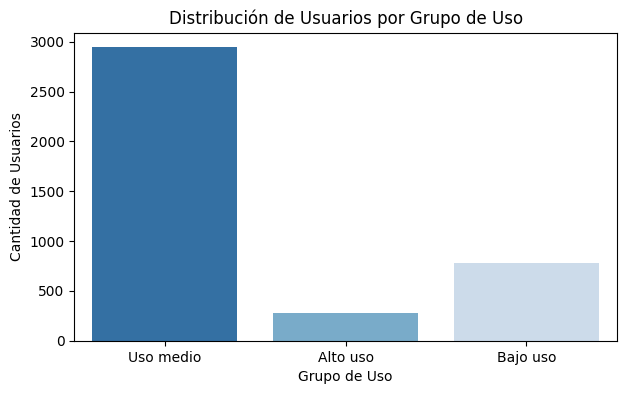

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualización de los segmentos por uso
plt.figure(figsize=(7, 4))
sns.countplot(data=user_profile, x="grupo_uso", palette="Blues_r")
plt.title("Distribución de Usuarios por Grupo de Uso")
plt.xlabel("Grupo de Uso")
plt.ylabel("Cantidad de Usuarios")
plt.show()

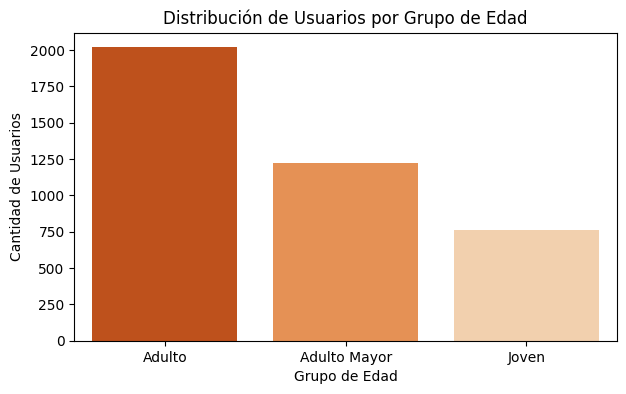

In [47]:
# Visualización de los segmentos por edad
plt.figure(figsize=(7, 4))
sns.countplot(data=user_profile, x="grupo_edad", palette="Oranges_r")
plt.title("Distribución de Usuarios por Grupo de Edad")
plt.xlabel("Grupo de Edad")
plt.ylabel("Cantidad de Usuarios")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Valores Centinela en Edad: Se detectó el valor -999 en la columna age de la tabla users que arruinaba la desviación estándar elevándola a 123.23. Se corrigió sustituyéndolo de forma limpia por la mediana real.
- Valores Categóricos Inválidos: Se encontró el carácter '?' en la columna city, el cual representaba un vacío de información y fue reemplazado exitosamente por pd.NA.
- Inconsistencias Temporales Graves: Se aislaron 40 registros con el año futuro imposible 2026 en la columna reg_date. Estos errores del sistema fueron neutralizados cambiándolos a pd.NaT.
- Ausencia Estructurada (MAR): Se comprobó que los 22,076 nulos de duration en mensajes y los 17,896 nulos de length en llamadas son completamente normales para el negocio y no errores de captura.


🔍 **Segmentos por Edad**
- Distribución Uniforme: La variable age (tras remover el -999) mostró una distribución simétrica y equilibrada de clientes jóvenes, adultos y adultos mayores. No se observa que la edad condicione fuertemente la elección del plan básico o premium.

📊 **Segmentos por Nivel de Uso**
- Comportamiento Comercial: Se observó un sesgo a la derecha en todas las variables de consumo. La mayoría de los usuarios con plan Basico se agrupan en consumos bajos, mientras que los clientes Premium estiran las gráficas hacia volúmenes altos en mensajes, llamadas y minutos.

➡️ Esto sugiere que ...
Los clientes reaccionan orgánicamente a los límites de sus planes. El plan Premium está siendo aprovechado de manera intensiva por el segmento de Alto uso, mientras que el plan Básico funciona como un esquema de control para usuarios que cuidan no sobrepasar sus umbrales de minutos o textos mensuales.

💡 **Recomendaciones**
- Respetar y Mantener los Patrones Extremos (Outliers): Los límites matemáticos del IQR marcaron como outliers a cualquiera que superara 11.5 mensajes, 10.5 llamadas o 61.85 minutos de llamada. La recomendación para el negocio es mantenerlos intactos en la base de datos, ya que no son errores del sistema; representan a nuestros usuarios más valiosos y activos de la red.
- Monitoreo de Consumo en Clientes Premium: Dado que los límites del IQR para uso "típico" son relativamente bajos (ej. ~11 mensajes), aquellos clientes que rompen exponencialmente estas barreras demuestran una alta lealtad y demanda. Se sugiere diseñar un programa de recompensas para este subgrupo de alto valor para mitigar el riesgo de abandono (churn).
- Bloqueo de Datos en Origen: Validar con el equipo de ingeniería de sistemas la implementación de restricciones en los formularios de registro de ConnectaTel para impedir de forma definitiva la entrada de años futuros como 2026 o edades en números negativos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`